# Bicep curls — last semester vs new watch
A visual comparison using one old right-arm recording labeled Typical and Anisha's new right-arm recording. Run all cells; change the file paths, windows, or selected axes below to explore other sessions.

The legacy notebook uses **gravityX**. The new watch records **total acceleration in g**, not a separate gravity estimate. These are related but different signals. Plots below explicitly retain that distinction; normalization is for viewing shapes, not proof of model compatibility. The old file's gravity units are treated as g, consistent with its approximately unit-length gravity vector; confirm the original logger's unit definitions before model work.

Dependencies: NumPy, SciPy, Matplotlib and the existing local HomeStretch recording reader. No training or source-data changes.

In [1]:
from pathlib import Path
import sys, csv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import uniform_filter1d
REPO = Path('/Users/jadechng/Desktop/HomeStretch/HomeStretchRepo')
OLD_FILE = REPO / 'Data/Raw/Typical/001_BicepCurl_R_T.csv'
NEW_FILE = Path('/Users/jadechng/Desktop/HomeStretch/recordings/1005/Anisha Bicep Curls_20261005-115528_1d1d07ea.csv')
OLD_WINDOW = None  # None shows the full old recording; otherwise (start_s,end_s)
NEW_WINDOW = (7.,29.)  # provisional first movement set; excludes reattachment
OLD_AXIS = 0  # legacy gravityX; 0=X, 1=Y, 2=Z
NEW_AXIS = 1  # Y used in the legacy watch adapter; exploratory, not verified alignment
NEW_SIGN = 1  # optionally -1 to inspect opposite axis direction
SMOOTH_SECONDS = 0.10
sys.path.insert(0,str(REPO/'signal-processing'))
from session_pipeline.reader import load_recording
COLORS = ['#2368A2','#D1495B','#2A9D6F']
with OLD_FILE.open(newline='') as f: rows=list(csv.DictReader(f))
old_t=np.array([float(r['seconds_elapsed']) for r in rows]);old_t-=old_t[0]
old_gravity=np.array([[float(r['gravity'+axis]) for axis in 'XYZ'] for r in rows])
assert np.all(np.diff(old_t)>0) and np.isfinite(old_gravity).all()
new_record=load_recording(NEW_FILE)
a=new_record['streams']['acceleration'];new_t=a[:,0];new_accel=a[:,1:4].copy()
new_accel[a[:,4]==0]=np.nan
new_accel[np.r_[False,np.diff(new_t)>.1]]=np.nan
print('Old:',OLD_FILE.name,'| duration:',round(old_t[-1],2),'s | sample rate:',round(1/np.median(np.diff(old_t)),1),'Hz')
print('New:',NEW_FILE.name,'| duration:',round(new_record['duration'],2),'s | sample rate:',round(1/np.median(np.diff(new_t)),1),'Hz')
print('New invalid acceleration samples:',int((a[:,4]==0).sum()),'of',len(a))
print('Old median gravity magnitude:',round(float(np.median(np.linalg.norm(old_gravity,axis=1))),3))
print('Labels: old filename says Typical; new technique label is not verified.')

Old: 001_BicepCurl_R_T.csv | duration: 43.09 s | sample rate: 99.7 Hz
New: Anisha Bicep Curls_20261005-115528_1d1d07ea.csv | duration: 81.28 s | sample rate: 50.0 Hz
New invalid acceleration samples: 180 of 4062
Old median gravity magnitude: 1.0
Labels: old filename says Typical; new technique label is not verified.


## 1. Full recordings, all axes
Old: gravity only. New: total acceleration. Shared vertical scale exposes amplitude differences. Gaps in the new trace indicate invalid/missing data. The shaded new interval is the first exercise set chosen for closer inspection.

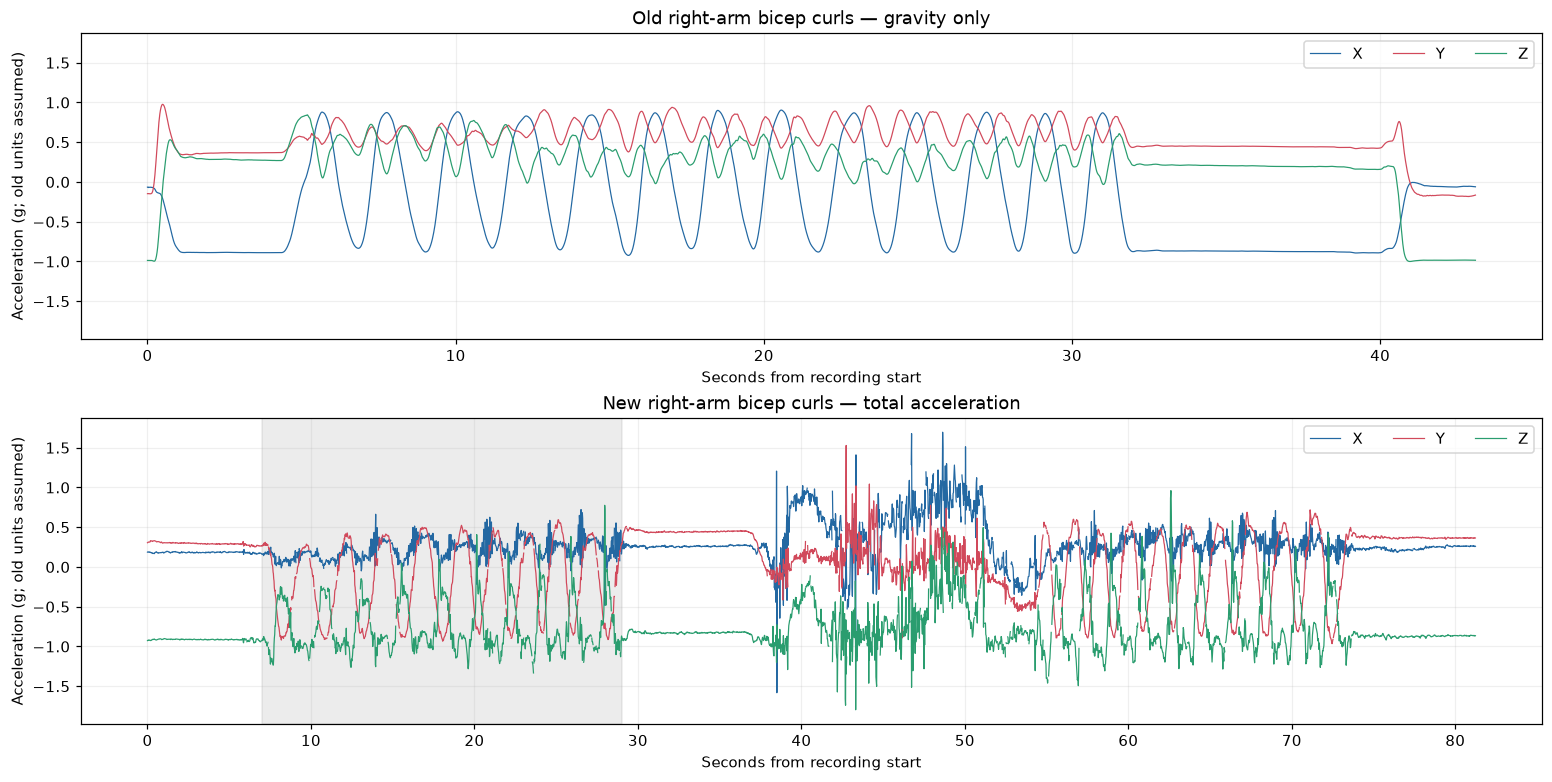

In [2]:
fig,axes=plt.subplots(2,1,figsize=(14,7),sharey=True,constrained_layout=True)
for k,color in enumerate(COLORS):
    axes[0].plot(old_t,old_gravity[:,k],color=color,label='XYZ'[k],lw=.8)
    axes[1].plot(new_t,new_accel[:,k],color=color,label='XYZ'[k],lw=.8)
axes[0].set_title('Old right-arm bicep curls — gravity only')
axes[1].set_title('New right-arm bicep curls — total acceleration')
if NEW_WINDOW:axes[1].axvspan(*NEW_WINDOW,color='gray',alpha=.15)
for ax in axes:
    ax.set_xlabel('Seconds from recording start');ax.set_ylabel('Acceleration (g; old units assumed)');ax.grid(alpha=.2);ax.legend(ncol=3)
plt.show()

## 2. Selected movement windows
The old window defaults to the full recording; adjust it after inspecting the first plot if it includes handling or rest. Each plot starts at zero seconds for readability. No repetition detection or time warping is applied.

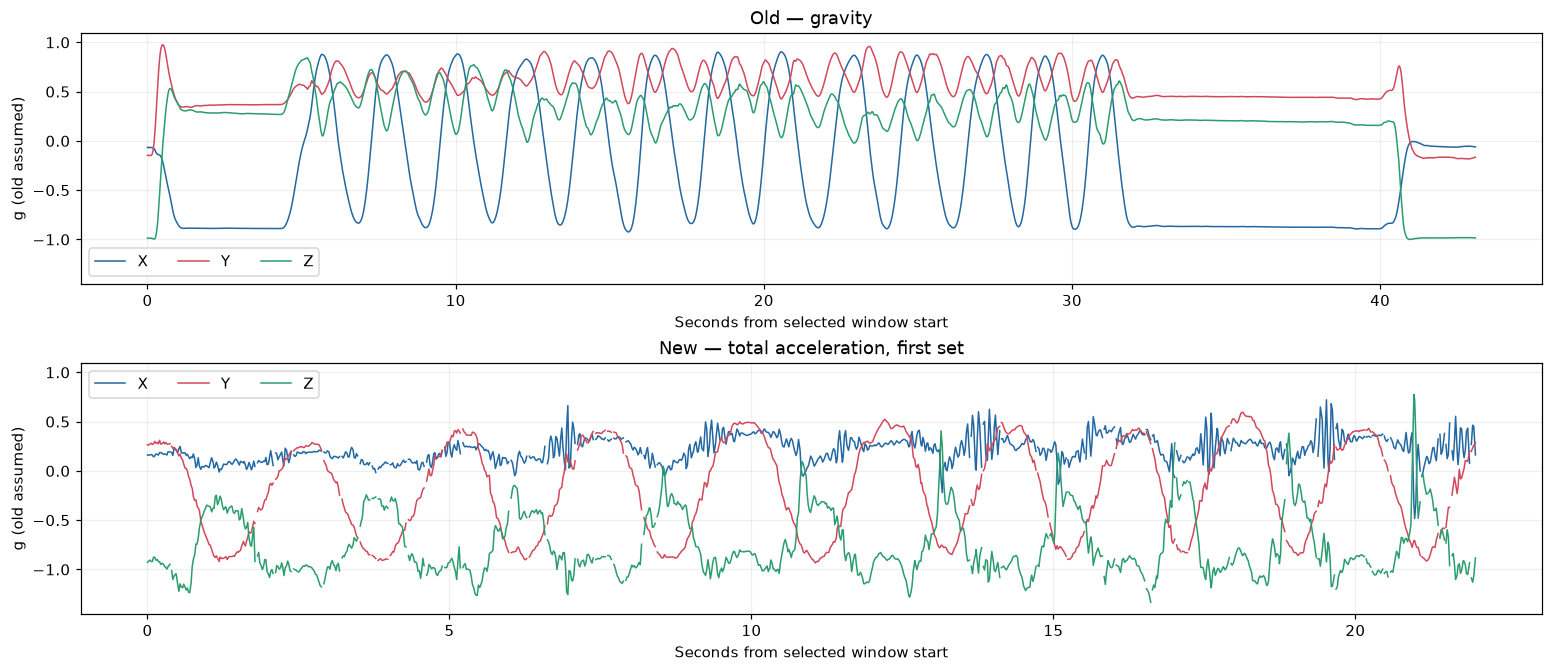

In [3]:
def select(t,y,window):
    keep=np.ones(len(t),dtype=bool) if window is None else (t>=window[0])&(t<=window[1])
    assert keep.sum()>5,'Select a longer window.'
    return t[keep]-t[keep][0],y[keep]
ot,oy=select(old_t,old_gravity,OLD_WINDOW)
nt,ny=select(new_t,new_accel,NEW_WINDOW)
fig,axes=plt.subplots(2,1,figsize=(14,6),sharey=True,constrained_layout=True)
for k,color in enumerate(COLORS):
    axes[0].plot(ot,oy[:,k],color=color,label='XYZ'[k],lw=1)
    axes[1].plot(nt,ny[:,k],color=color,label='XYZ'[k],lw=1)
for ax,title in zip(axes,['Old — gravity','New — total acceleration, first set']):
    ax.set_title(title);ax.set_xlabel('Seconds from selected window start');ax.set_ylabel('g (old assumed)');ax.grid(alpha=.2);ax.legend(ncol=3)
plt.show()

## 3. Legacy input versus new watch input: original scale and standardized shape
Left column retains signal units. Right column subtracts each selected signal's mean and divides by its standard deviation, so patterns can be inspected without baseline or overall size dominating.

A short moving average uses the same duration for both sources, applied only within contiguous finite runs. It does not bridge missing data or turn total acceleration into a gravity estimate. Sample rates may differ, so smoothing windows are computed in seconds. These display statistics must not be reused as a fitted model scaler.

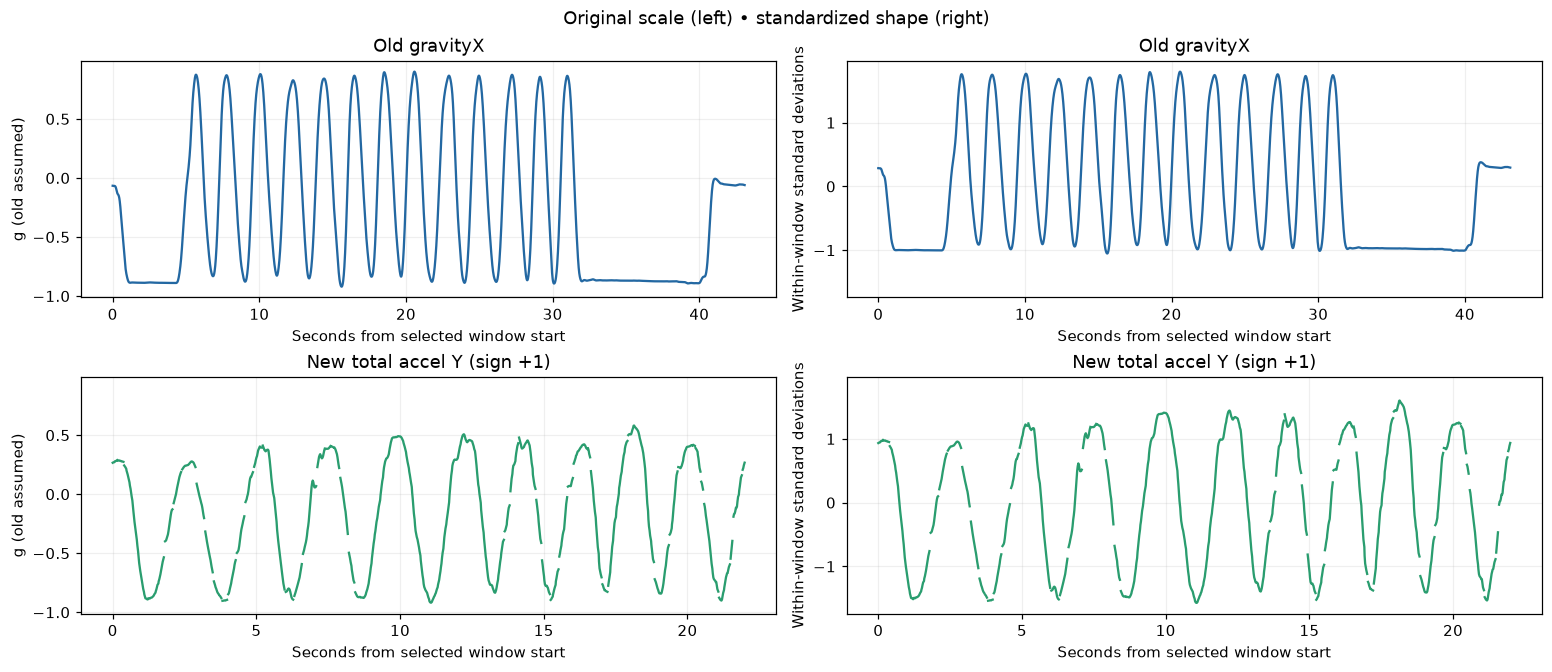

In [4]:
def smooth_runs(t,y):
    out=np.full_like(y,np.nan,dtype=float)
    good=np.flatnonzero(np.isfinite(y))
    runs=np.split(good,np.flatnonzero(np.diff(good)>1)+1)
    window=max(1,int(round(SMOOTH_SECONDS/np.median(np.diff(t)))))
    for ids in runs:
        if len(ids):out[ids]=uniform_filter1d(y[ids],size=min(window,len(ids)),mode='nearest')
    return out

def standardize(y):
    spread=np.nanstd(y)
    assert spread>1e-8,'Selected signal has negligible variation.'
    return (y-np.nanmean(y))/spread
assert NEW_SIGN in (-1,1)
os=smooth_runs(ot,oy[:,OLD_AXIS]);ns=smooth_runs(nt,ny[:,NEW_AXIS])*NEW_SIGN
fig,axes=plt.subplots(2,2,figsize=(14,6),sharey='col',constrained_layout=True)
for row,(t,s,label,color) in enumerate([(ot,os,'Old gravity'+'XYZ'[OLD_AXIS],COLORS[0]),(nt,ns,'New total accel '+'XYZ'[NEW_AXIS]+f' (sign {NEW_SIGN:+d})',COLORS[2])]):
    axes[row,0].plot(t,s,color=color);axes[row,1].plot(t,standardize(s),color=color)
    for ax in axes[row]:ax.set_title(label);ax.set_xlabel('Seconds from selected window start');ax.grid(alpha=.2)
    axes[row,0].set_ylabel('g (old assumed)');axes[row,1].set_ylabel('Within-window standard deviations')
fig.suptitle('Original scale (left) • standardized shape (right)')
plt.show()

### Reading these plots
Look for recurring movement patterns and interruptions. Change `OLD_AXIS` and `NEW_AXIS` to inspect channels, but do not interpret a visual match as anatomical alignment. Use the same chosen settings consistently rather than selecting a different best-looking axis for each repetition.

This notebook compares raw recordings from the old dataset with new recordings. It does not establish that this particular old file was in the saved model's training split. The old source is `Data/Raw/Typical`; the legacy training notebook references gravityX, while the Mbient adapter uses total acceleration Y. That signal difference remains visible rather than being silently called equivalent.